<a href="https://colab.research.google.com/github/ranimiftah12345678/ML_22_Ranimiftah/blob/main/JS08/JS08_TUGAS01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Setup dan Upload Data

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score
from scipy.cluster.hierarchy import linkage, dendrogram

df = pd.read_csv("/content/CC_Customer_Dataset.csv")

print(df.shape)
print(df.columns.tolist())
df.head()

(660, 7)
['Sl_No', 'Customer Key', 'Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']


,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


Cek Data

In [ ]:
df.info()
print("\nMissing value:\n", df.isnull().sum())
print("\nDuplikat:", df.duplicated().sum())
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB

Missing value:
 Sl_No                  0
Customer Key           0
Avg_Credit_Limit       0
Total_Credit_Cards     0
Total_visits_bank      0
Total_visits_online    0
Total_calls_made       0
dtype: int64

Duplikat: 0


,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
count,660.000000,660.000000,660.000000,660.000000,660.000000,660.000000,660.000000
mean,330.500000,55141.443939,34574.242424,4.706061,2.403030,2.606061,3.583333
std,190.669872,25627.772200,37625.487804,2.167835,1.631813,2.935724,2.865317
min,1.000000,11265.000000,3000.000000,1.000000,0.000000,0.000000,0.000000
25%,165.750000,33825.250000,10000.000000,3.000000,1.000000,1.000000,1.000000
50%,330.500000,53874.500000,18000.000000,5.000000,2.000000,2.000000,3.000000
75%,495.250000,77202.500000,48000.000000,6.000000,4.000000,4.000000,5.000000
max,660.000000,99843.000000,200000.000000,10.000000,5.000000,15.000000,10.000000


Pilih Variabel yang Dapat Digunakan

In [ ]:
# Buang kolom identitas (Sl_No, Customer Key, dan sejenisnya)
id_cols = [c for c in df.columns
           if c.strip().lower().replace(" ", "_") in ("sl_no", "customer_key", "customerkey", "id", "no")]
print("Kolom ID yang dibuang:", id_cols)

df_clean = df.drop(columns=id_cols).drop_duplicates().reset_index(drop=True)
features = df_clean.select_dtypes(include=np.number).columns.tolist()
print("Fitur yang dipakai:", features)

X = df_clean[features]

# Standarisasi, wajib karena Avg_Credit_Limit skalanya jauh lebih besar dari kolom lain
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

Kolom ID yang dibuang: ['Sl_No', 'Customer Key']
Fitur yang dipakai: ['Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']


Dendrogram (untuk menentukan jumlah cluster)

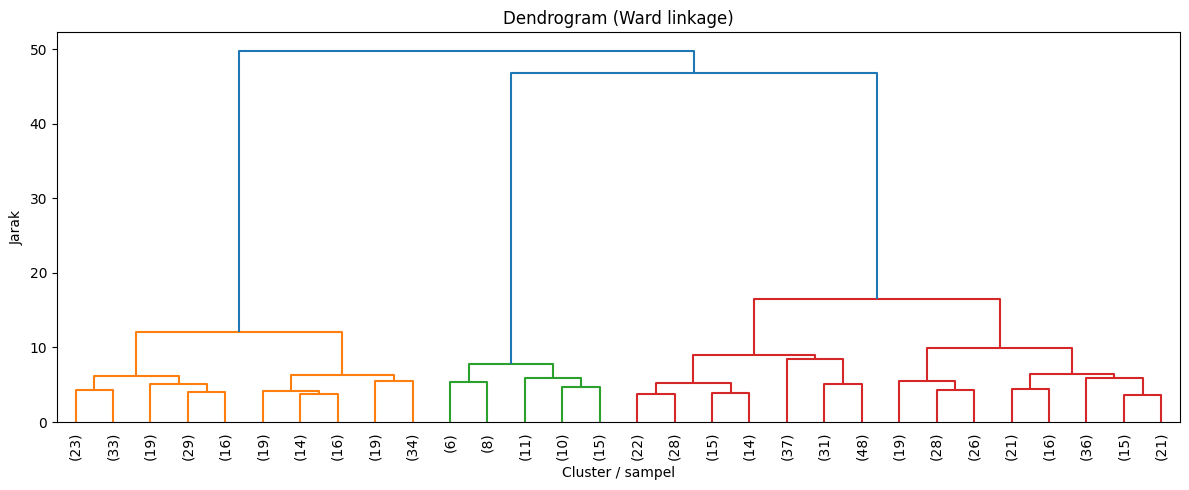

In [ ]:
Z = linkage(X_scaled, method="ward")
plt.figure(figsize=(12, 5))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90)
plt.title("Dendrogram (Ward linkage)")
plt.xlabel("Cluster / sampel")
plt.ylabel("Jarak")
plt.tight_layout()
plt.show()

Bandingkan beberapa nilai k

In [ ]:
hasil = []
for k in range(2, 8):
    lab = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X_scaled)
    hasil.append({"k": k,
                  "silhouette": silhouette_score(X_scaled, lab),
                  "DBI": davies_bouldin_score(X_scaled, lab)})
hasil = pd.DataFrame(hasil)
print(hasil.round(4))

   k  silhouette     DBI
0  2      0.4173  0.9333
1  3      0.5153  0.6802
2  4      0.3476  1.1570
3  5      0.2564  1.3900
4  6      0.2301  1.3816
5  7      0.2232  1.5105


Model akhir Agglomerative Clustering

In [ ]:
K = 3

model = AgglomerativeClustering(n_clusters=K, linkage="ward")
labels = model.fit_predict(X_scaled)
df_clean["Cluster"] = labels

print(df_clean["Cluster"].value_counts().sort_index())
print()
df_clean.groupby("Cluster")[features].mean().round(2)

Cluster
0    377
1    222
2     50
Name: count, dtype: int64



,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
Cluster,,,,,
0,34143.24,5.52,3.49,0.98,1.99
1,12216.22,2.42,0.95,3.55,6.88
2,141040.00,8.74,0.60,10.90,1.08


Scatterplot Avg_Credit_Limit vs Total_credit_card

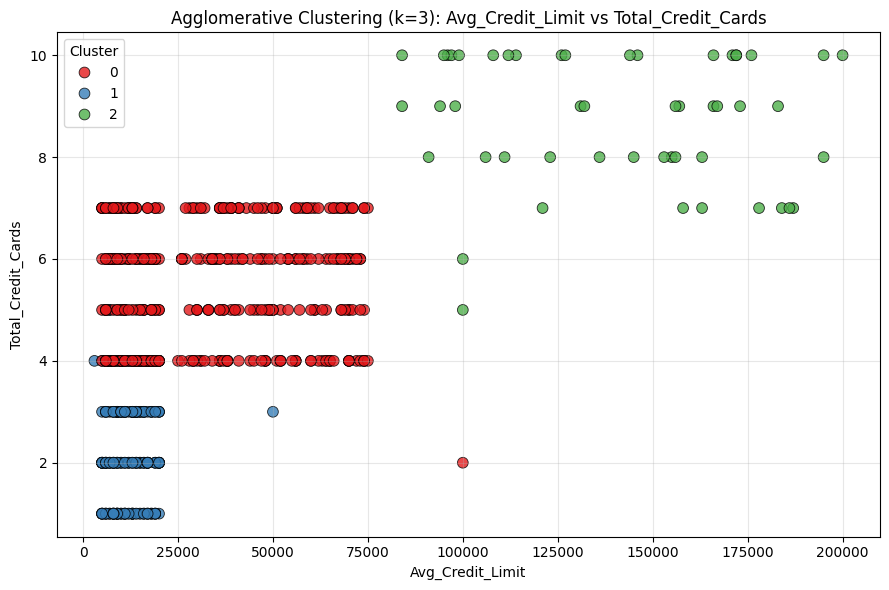

In [ ]:
# Deteksi nama kolom secara fleksibel
def cari_kolom(df, kunci):
    for c in df.columns:
        if kunci in c.lower().replace(" ", "_"):
            return c
    raise KeyError(f"Kolom berisi '{kunci}' tidak ditemukan: {list(df.columns)}")

col_limit = cari_kolom(df_clean, "avg_credit_limit")
col_cards = cari_kolom(df_clean, "total_credit_card")

plt.figure(figsize=(9, 6))
sns.scatterplot(data=df_clean, x=col_limit, y=col_cards,
                hue="Cluster", palette="Set1", s=60, alpha=0.8, edgecolor="k")
plt.title(f"Agglomerative Clustering (k={K}): {col_limit} vs {col_cards}")
plt.xlabel(col_limit)
plt.ylabel(col_cards)
plt.legend(title="Cluster")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Silhouette score dan DBI

In [ ]:
sil = silhouette_score(X_scaled, labels)
dbi = davies_bouldin_score(X_scaled, labels)

print(f"Jumlah cluster         : {K}")
print(f"Silhouette Score       : {sil:.4f}")
print(f"Davies-Bouldin Index   : {dbi:.4f}")

Jumlah cluster         : 3
Silhouette Score       : 0.5153
Davies-Bouldin Index   : 0.6802
